<a href="https://colab.research.google.com/github/balajibalu09/IAS-PROJECT/blob/main/Copy_of_Pediatric_Pneumonia_EfficientNet_B3_GradCAM_Website.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pediatric Chest X-ray Pneumonia Classification
## EfficientNet-B3 + Grad-CAM + Gradio Website

**Pipeline**

Kaggle Pediatric Chest X-ray Dataset → Automatic Download → Extraction → EfficientNet-B3 → NORMAL/PNEUMONIA → Evaluation → Grad-CAM → Gradio Web App




In [ ]:
# ============================================================
# CELL 1 - INSTALL REQUIRED PACKAGES
# ============================================================

!pip install -q kaggle
!pip install -q opencv-python
!pip install -q matplotlib
!pip install -q seaborn

In [ ]:
# ============================================================
# CELL 2 - IMPORT LIBRARIES
# ============================================================

import os
import random
import shutil
import zipfile
import json

import numpy as np
import matplotlib.pyplot as plt
import cv2

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import (
    DataLoader,
    Subset
)

from torchvision import (
    datasets,
    transforms,
    models
)

print("All libraries imported successfully.")

All libraries imported successfully.


In [ ]:
# ============================================================
# CELL 3 - CHECK GPU
# ============================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

else:

    print(
        "WARNING: GPU not available."
    )

    print(
        "Go to Runtime > Change runtime type > GPU"
    )

Device: cuda
GPU: Tesla T4


In [ ]:
# ============================================================
# 3. KAGGLE AUTHENTICATION
# ============================================================

import os

# IMPORTANT:
# Replace with your NEW Kaggle API token.
# Do NOT use the token previously exposed in the chat.

os.environ["KAGGLE_API_TOKEN"] = "KGAT\_b07ea387222da675475ad4a71a5ab816"

print("Kaggle authentication configured.")

Kaggle authentication configured.


<>:11: SyntaxWarning: invalid escape sequence '\_'
<>:11: SyntaxWarning: invalid escape sequence '\_'
/tmp/ipykernel_2247/3372770325.py:11: SyntaxWarning: invalid escape sequence '\_'
  os.environ["KAGGLE_API_TOKEN"] = "KGAT\_b07ea387222da675475ad4a71a5ab816"


In [ ]:
# ============================================================
# CELL 5 - DOWNLOAD KAGGLE DATASET
# ============================================================

DATASET_NAME = (
    "andrewmvd/pediatric-pneumonia-chest-xray"
)

DOWNLOAD_DIR = "/content/kaggle_dataset"

os.makedirs(
    DOWNLOAD_DIR,
    exist_ok=True
)

print("Downloading dataset...")

!kaggle datasets download \
    -d andrewmvd/pediatric-pneumonia-chest-xray \
    -p /content/kaggle_dataset

print("✓ Dataset download completed.")

Dataset URL: https://www.kaggle.com/datasets/andrewmvd/pediatric-pneumonia-chest-xray
License(s): Attribution 4.0 International (CC BY 4.0)
100% 1.14G/1.14G [00:31<00:00, 39.1MB/s]

✓ Dataset download completed.


In [ ]:
# ============================================================
# CELL 6 - EXTRACT DATASET
# ============================================================

zip_files = [
    f
    for f in os.listdir(
        DOWNLOAD_DIR
    )
    if f.endswith(".zip")
]

if not zip_files:

    raise FileNotFoundError(
        "Dataset ZIP file not found."
    )

zip_path = os.path.join(
    DOWNLOAD_DIR,
    zip_files[0]
)

EXTRACT_DIR = "/content/pediatric_dataset"

os.makedirs(
    EXTRACT_DIR,
    exist_ok=True
)

print(
    "Extracting:",
    zip_path
)

with zipfile.ZipFile(
    zip_path,
    "r"
) as zip_ref:

    zip_ref.extractall(
        EXTRACT_DIR
    )

print(
    "✓ Dataset extracted."
)

Extracting: /content/kaggle_dataset/pediatric-pneumonia-chest-xray.zip
✓ Dataset extracted.


In [ ]:
# ============================================================
# CELL 7 - FIND DATASET FOLDERS
# ============================================================

def find_folder(
    root,
    folder_name
):

    for current_root, dirs, files_list in os.walk(root):

        for directory in dirs:

            if directory.lower() == folder_name.lower():

                return os.path.join(
                    current_root,
                    directory
                )

    return None


TRAIN_DIR = find_folder(
    EXTRACT_DIR,
    "train"
)

TEST_DIR = find_folder(
    EXTRACT_DIR,
    "test"
)


print("========================================")
print("DATASET PATHS")
print("========================================")

print(
    "TRAIN_DIR:",
    TRAIN_DIR
)

print(
    "TEST_DIR:",
    TEST_DIR
)


if TRAIN_DIR is None:

    raise FileNotFoundError(
        "Training folder was not found."
    )


if TEST_DIR is None:

    raise FileNotFoundError(
        "Test folder was not found."
    )

DATASET PATHS
TRAIN_DIR: /content/pediatric_dataset/Pediatric Chest X-ray Pneumonia/train
TEST_DIR: /content/pediatric_dataset/Pediatric Chest X-ray Pneumonia/test


In [ ]:
# ============================================================
# CELL 7 - FIND DATASET FOLDERS
# ============================================================

def find_folder(
    root,
    folder_name
):

    for current_root, dirs, files_list in os.walk(root):

        for directory in dirs:

            if directory.lower() == folder_name.lower():

                return os.path.join(
                    current_root,
                    directory
                )

    return None


TRAIN_DIR = find_folder(
    EXTRACT_DIR,
    "train"
)

TEST_DIR = find_folder(
    EXTRACT_DIR,
    "test"
)


print("========================================")
print("DATASET PATHS")
print("========================================")

print(
    "TRAIN_DIR:",
    TRAIN_DIR
)

print(
    "TEST_DIR:",
    TEST_DIR
)


if TRAIN_DIR is None:

    raise FileNotFoundError(
        "Training folder was not found."
    )


if TEST_DIR is None:

    raise FileNotFoundError(
        "Test folder was not found."
    )

DATASET PATHS
TRAIN_DIR: /content/pediatric_dataset/Pediatric Chest X-ray Pneumonia/train
TEST_DIR: /content/pediatric_dataset/Pediatric Chest X-ray Pneumonia/test


In [ ]:
# ============================================================
# CELL 9 - CONFIGURATION
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():

    torch.cuda.manual_seed_all(
        SEED
    )


IMAGE_SIZE = 300

BATCH_SIZE = 16

NUM_EPOCHS = 5

LEARNING_RATE = 1e-4

MODEL_PATH = (
    "/content/"
    "Pediatric_Pneumonia_EfficientNet_B3.pth"
)


print("========================================")
print("CONFIGURATION")
print("========================================")

print(
    "Image size:",
    IMAGE_SIZE
)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Epochs:",
    NUM_EPOCHS
)

print(
    "Learning rate:",
    LEARNING_RATE
)

print(
    "Model path:",
    MODEL_PATH
)

CONFIGURATION
Image size: 300
Batch size: 16
Epochs: 5
Learning rate: 0.0001
Model path: /content/Pediatric_Pneumonia_EfficientNet_B3.pth


In [ ]:
# ============================================================
# CELL 10 - IMAGE TRANSFORMS
# ============================================================

train_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        10
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


test_transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


print(
    "✓ Image transforms ready."
)

✓ Image transforms ready.


In [ ]:
# ============================================================
# CELL 11 - LOAD DATASET
# ============================================================

train_full_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

train_eval_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=test_transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=test_transform
)


classes = train_full_dataset.classes


print("========================================")
print("DATASET INFORMATION")
print("========================================")

print(
    "Classes:",
    classes
)

print(
    "Total training images:",
    len(train_full_dataset)
)

print(
    "Total test images:",
    len(test_dataset)
)


if len(classes) != 2:

    raise ValueError(
        f"Expected 2 classes, found: {classes}"
    )

DATASET INFORMATION
Classes: ['NORMAL', 'PNEUMONIA']
Total training images: 5232
Total test images: 624


In [ ]:
# ============================================================
# CELL 12 - TRAIN / VALIDATION SPLIT
# ============================================================

generator = torch.Generator().manual_seed(
    SEED
)


indices = list(
    range(
        len(train_full_dataset)
    )
)

random.Random(SEED).shuffle(
    indices
)


train_size = int(
    0.8 * len(indices)
)

train_indices = indices[
    :train_size
]

val_indices = indices[
    train_size:
]


train_dataset = Subset(
    train_full_dataset,
    train_indices
)

val_dataset = Subset(
    train_eval_dataset,
    val_indices
)


print(
    "Training images:",
    len(train_dataset)
)

print(
    "Validation images:",
    len(val_dataset)
)

Training images: 4185
Validation images: 1047


In [ ]:
# ============================================================
# CELL 13 - DATA LOADERS
# ============================================================

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)


val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)


test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)


print("========================================")
print("DATA LOADERS READY")
print("========================================")

print(
    "Training batches:",
    len(train_loader)
)

print(
    "Validation batches:",
    len(val_loader)
)

print(
    "Test batches:",
    len(test_loader)
)

DATA LOADERS READY
Training batches: 262
Validation batches: 66
Test batches: 39


In [ ]:
# ============================================================
# CELL 14 - EFFICIENTNET-B3
# ============================================================

print(
    "Loading EfficientNet-B3..."
)


weights = (
    models.EfficientNet_B3_Weights.DEFAULT
)


model = models.efficientnet_b3(
    weights=weights
)


# ------------------------------------------------------------
# Replace classifier
# ------------------------------------------------------------

num_features = (
    model.classifier[1].in_features
)


model.classifier[1] = nn.Linear(
    num_features,
    2
)


# ------------------------------------------------------------
# Freeze backbone
# ------------------------------------------------------------

for parameter in model.parameters():

    parameter.requires_grad = False


# ------------------------------------------------------------
# IMPORTANT:
# Unfreeze final feature blocks
# for training + Grad-CAM
# ------------------------------------------------------------

for parameter in (
    model.features[-2:].parameters()
):

    parameter.requires_grad = True


# Classifier trainable

for parameter in (
    model.classifier.parameters()
):

    parameter.requires_grad = True


model = model.to(
    DEVICE
)


criterion = nn.CrossEntropyLoss()


optimizer = optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)


print("========================================")
print("EFFICIENTNET-B3 READY")
print("========================================")

print(
    "Device:",
    DEVICE
)

print(
    "Classes:",
    classes
)

Loading EfficientNet-B3...
Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 162MB/s]


EFFICIENTNET-B3 READY
Device: cuda
Classes: ['NORMAL', 'PNEUMONIA']


In [ ]:
# ============================================================
# CELL 15 - TRAIN + VALIDATE
# ============================================================

train_losses = []
val_losses = []

train_accs = []
val_accs = []

best_val_acc = 0.0


def run_epoch(
    loader,
    training=True
):

    if training:

        model.train()

    else:

        model.eval()


    running_loss = 0.0

    correct = 0

    total = 0


    context = (
        torch.enable_grad()
        if training
        else torch.no_grad()
    )


    with context:

        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )


            if training:

                optimizer.zero_grad()


            outputs = model(
                images
            )


            loss = criterion(
                outputs,
                labels
            )


            if training:

                loss.backward()

                optimizer.step()


            running_loss += (
                loss.item()
                * images.size(0)
            )


            predictions = torch.argmax(
                outputs,
                dim=1
            )


            correct += (
                predictions == labels
            ).sum().item()


            total += labels.size(0)


    return (
        running_loss / total,
        correct / total
    )


print("========================================")
print("STARTING TRAINING")
print("========================================")


for epoch in range(
    NUM_EPOCHS
):

    train_loss, train_acc = run_epoch(
        train_loader,
        training=True
    )


    val_loss, val_acc = run_epoch(
        val_loader,
        training=False
    )


    train_losses.append(
        train_loss
    )

    val_losses.append(
        val_loss
    )

    train_accs.append(
        train_acc
    )

    val_accs.append(
        val_acc
    )


    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )


    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            MODEL_PATH
        )

        print(
            "✓ Best model saved."
        )


print("\n========================================")
print("TRAINING COMPLETE")
print("========================================")

print(
    f"Best validation accuracy: "
    f"{best_val_acc * 100:.2f}%"
)

print(
    "Model:",
    MODEL_PATH
)

STARTING TRAINING
Epoch 1/5 | Train Loss: 0.2395 | Train Acc: 0.9054 | Val Loss: 0.1231 | Val Acc: 0.9522
✓ Best model saved.
Epoch 2/5 | Train Loss: 0.1181 | Train Acc: 0.9539 | Val Loss: 0.0793 | Val Acc: 0.9694
✓ Best model saved.
Epoch 3/5 | Train Loss: 0.0990 | Train Acc: 0.9646 | Val Loss: 0.0718 | Val Acc: 0.9704
✓ Best model saved.
Epoch 4/5 | Train Loss: 0.0918 | Train Acc: 0.9644 | Val Loss: 0.0596 | Val Acc: 0.9799
✓ Best model saved.
Epoch 5/5 | Train Loss: 0.0835 | Train Acc: 0.9687 | Val Loss: 0.0654 | Val Acc: 0.9733

TRAINING COMPLETE
Best validation accuracy: 97.99%
Model: /content/Pediatric_Pneumonia_EfficientNet_B3.pth


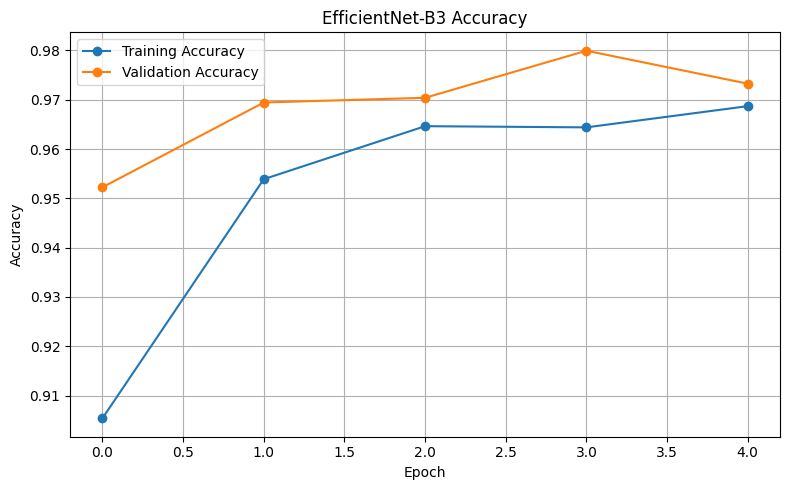

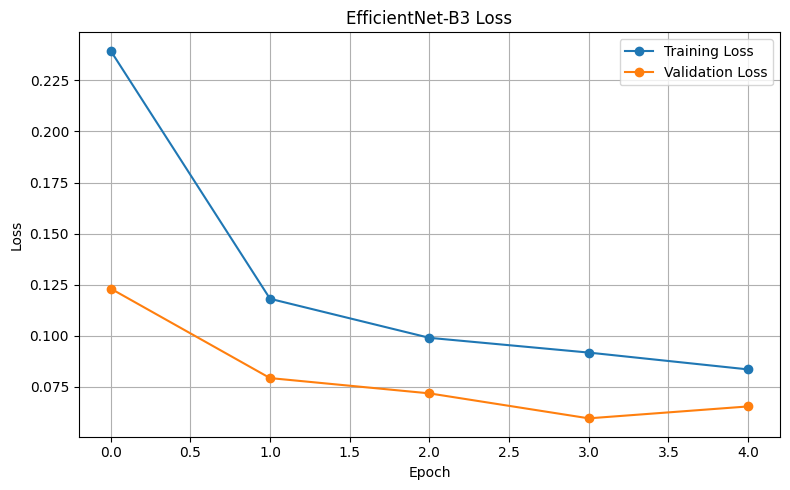

In [ ]:
# ============================================================
# CELL 16 - TRAINING GRAPHS
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    train_accs,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    val_accs,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "EfficientNet-B3 Accuracy"
)

plt.legend()

plt.grid()

plt.tight_layout()

plt.show()


plt.figure(
    figsize=(8, 5)
)

plt.plot(
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "EfficientNet-B3 Loss"
)

plt.legend()

plt.grid()

plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# CELL 17 - LOAD BEST MODEL
# ============================================================

model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=DEVICE
    )
)

model = model.to(
    DEVICE
)

model.eval()


print(
    "✓ Best EfficientNet-B3 model loaded."
)

print(
    "Model:",
    MODEL_PATH
)

✓ Best EfficientNet-B3 model loaded.
Model: /content/Pediatric_Pneumonia_EfficientNet_B3.pth


SAMPLE X-RAY IMAGES


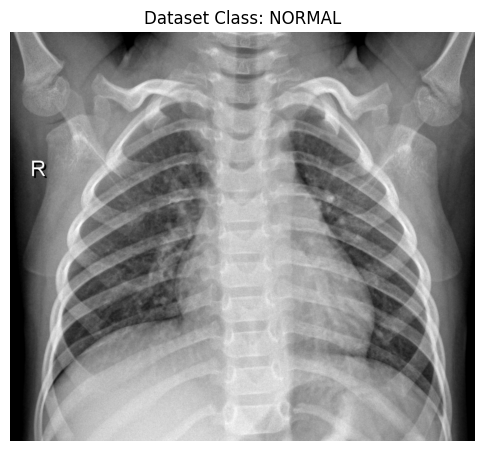

File: /content/pediatric_dataset/Pediatric Chest X-ray Pneumonia/train/NORMAL/NORMAL2-IM-0918-0001.jpeg


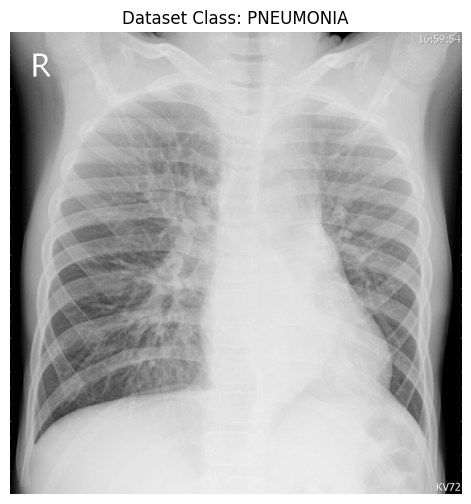

File: /content/pediatric_dataset/Pediatric Chest X-ray Pneumonia/train/PNEUMONIA/person1557_bacteria_4063.jpeg


In [ ]:
# ============================================================
# CELL 18 - DISPLAY SAMPLE X-RAYS
# ============================================================

print(
    "========================================"
)

print(
    "SAMPLE X-RAY IMAGES"
)

print(
    "========================================"
)


for class_name in classes:

    class_folder = os.path.join(
        TRAIN_DIR,
        class_name
    )


    image_files = [

        f

        for f in os.listdir(
            class_folder
        )

        if f.lower().endswith(
            (
                ".jpg",
                ".jpeg",
                ".png"
            )
        )

    ]


    if not image_files:

        continue


    sample_file = random.choice(
        image_files
    )


    sample_path = os.path.join(
        class_folder,
        sample_file
    )


    image = Image.open(
        sample_path
    ).convert(
        "RGB"
    )


    plt.figure(
        figsize=(6, 6)
    )


    plt.imshow(
        image
    )


    plt.title(
        f"Dataset Class: {class_name}"
    )


    plt.axis(
        "off"
    )


    plt.show()


    print(
        "File:",
        sample_path
    )

In [ ]:
# ============================================================
# CELL 19 - GRAD-CAM SETUP
# ============================================================

# Install Grad-CAM library
!pip install -q grad-cam


# ============================================================
# IMPORTS
# ============================================================

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

import numpy as np
import cv2


# ============================================================
# EFFICIENTNET-B3 TARGET LAYER
# ============================================================

target_layer = model.features[-1]


print("✓ Grad-CAM setup completed.")
print()
print("Target layer:")
print(target_layer)


# ============================================================
# CREATE GRAD-CAM OBJECT
# ============================================================

cam = GradCAM(
    model=model,
    target_layers=[target_layer]
)


print()
print("✓ Grad-CAM object created successfully.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✓ Grad-CAM setup completed.

Target layer:
Conv2dNormActivation(
  (0): Conv2d(384, 1536, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (1): BatchNorm2d(1536, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)

✓ Grad-CAM object created successfully.


In [ ]:
# ============================================================
# CELL 19A - INFERENCE TRANSFORM
# ============================================================

from torchvision import transforms

inference_transform = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("✓ Inference transform created.")

✓ Inference transform created.


In [ ]:
# ============================================================
# CELL 20 - GRAD-CAM WITHOUT AI FOCUS BOX
# ============================================================

def predict_with_gradcam(image):

    # --------------------------------------------------------
    # Load image
    # --------------------------------------------------------

    if isinstance(image, str):

        original = Image.open(
            image
        ).convert("RGB")

    else:

        original = image.convert(
            "RGB"
        )


    # --------------------------------------------------------
    # Resize
    # --------------------------------------------------------

    original_resized = original.resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    )


    original_np = (
        np.array(
            original_resized
        ).astype(
            np.float32
        ) / 255.0
    )


    # --------------------------------------------------------
    # Prepare model input
    # --------------------------------------------------------

    input_tensor = (
        inference_transform(
            original_resized
        )
        .unsqueeze(0)
        .to(DEVICE)
    )


    # --------------------------------------------------------
    # Classification
    # --------------------------------------------------------

    model.eval()

    with torch.no_grad():

        outputs = model(
            input_tensor
        )

        probabilities = torch.softmax(
            outputs,
            dim=1
        )[0]

        predicted_index = torch.argmax(
            probabilities
        ).item()

        confidence = probabilities[
            predicted_index
        ].item()


    predicted_class = classes[
        predicted_index
    ]


    # --------------------------------------------------------
    # Grad-CAM
    # --------------------------------------------------------

    with torch.enable_grad():

        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=[
                ClassifierOutputTarget(
                    predicted_index
                )
            ]
        )[0]


    # --------------------------------------------------------
    # Normalize CAM
    # --------------------------------------------------------

    grayscale_cam = np.maximum(
        grayscale_cam,
        0
    )


    if grayscale_cam.max() > 0:

        grayscale_cam = (
            grayscale_cam /
            grayscale_cam.max()
        )


    # --------------------------------------------------------
    # Create heatmap
    # --------------------------------------------------------

    heatmap = cv2.applyColorMap(
        np.uint8(
            grayscale_cam * 255
        ),
        cv2.COLORMAP_JET
    )


    heatmap = cv2.cvtColor(
        heatmap,
        cv2.COLOR_BGR2RGB
    )


    # --------------------------------------------------------
    # Overlay heatmap on X-ray
    # --------------------------------------------------------

    overlay = (
        0.45 * heatmap +
        0.55 * (
            original_np * 255
        )
    )


    overlay = np.clip(
        overlay,
        0,
        255
    ).astype(
        np.uint8
    )


    # --------------------------------------------------------
    # Return EXACTLY 3 values
    # --------------------------------------------------------

    return (
        predicted_class,
        confidence,
        overlay
    )


print("✓ Grad-CAM prediction ready.")
print("✓ AI focus box/circle removed.")
print("✓ Function returns exactly 3 values.")

✓ Grad-CAM prediction ready.
✓ AI focus box/circle removed.
✓ Function returns exactly 3 values.


Upload a chest X-ray image:


Saving PNEUMONIA_3.jpg to PNEUMONIA_3.jpg

Image: PNEUMONIA_3.jpg

AI CLASSIFICATION RESULT
Class: PNEUMONIA
Confidence: 99.91%


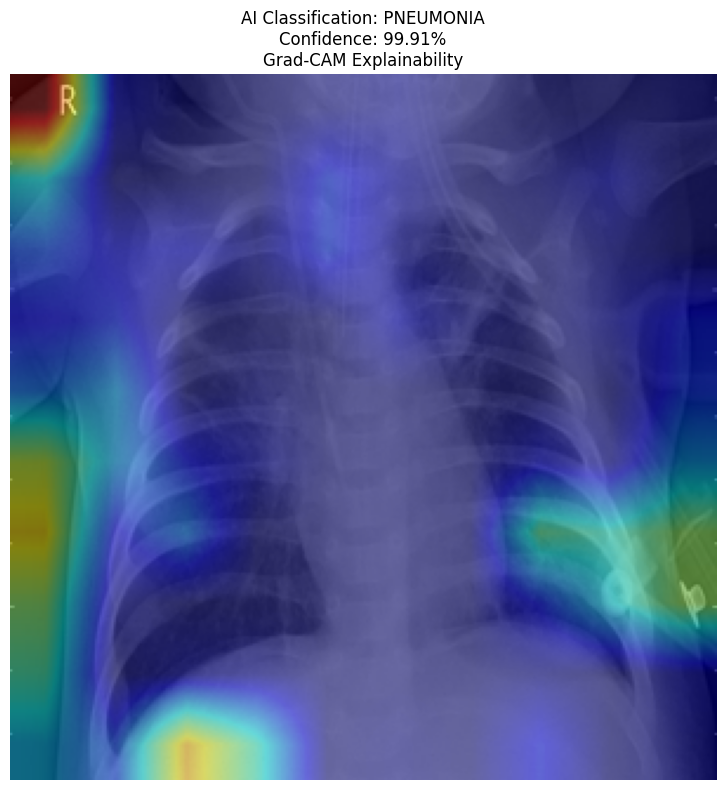

In [ ]:
# ============================================================
# CELL 21 - TEST IMAGE
# ============================================================

from google.colab import files
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Upload X-ray
# ------------------------------------------------------------

print("Upload a chest X-ray image:")

uploaded = files.upload()


if len(uploaded) == 0:

    raise ValueError(
        "No image uploaded."
    )


image_path = list(
    uploaded.keys()
)[0]


print(
    "\nImage:",
    image_path
)


# ------------------------------------------------------------
# Prediction + Grad-CAM
# ------------------------------------------------------------

(
    predicted_class,
    confidence,
    heatmap
) = predict_with_gradcam(
    image_path
)


# ------------------------------------------------------------
# Result
# ------------------------------------------------------------

print(
    "\n========================================"
)

print(
    "AI CLASSIFICATION RESULT"
)

print(
    "========================================"
)

print(
    "Class:",
    predicted_class
)

print(
    "Confidence:",
    f"{confidence * 100:.2f}%"
)

print(
    "========================================"
)


# ------------------------------------------------------------
# Display Grad-CAM
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 8)
)


plt.imshow(
    heatmap
)


plt.title(
    f"AI Classification: {predicted_class}\n"
    f"Confidence: {confidence * 100:.2f}%\n"
    f"Grad-CAM Explainability"
)


plt.axis(
    "off"
)


plt.tight_layout()

plt.show()

In [ ]:
# ============================================================
# CELL 23 - SAVE GRAD-CAM RESULT
# ============================================================

result_path = "/content/gradcam_result.jpg"


# ------------------------------------------------------------
# heatmap_image is already uint8 (0-255)
# ------------------------------------------------------------

result_image = heatmap_image


# ------------------------------------------------------------
# Save image
# ------------------------------------------------------------

Image.fromarray(
    result_image
).save(
    result_path,
    quality=95
)


print(
    "✓ Grad-CAM result saved:"
)

print(
    result_path
)

✓ Grad-CAM result saved:
/content/gradcam_result.jpg


In [ ]:
# ============================================================
# CELL 24 - DOWNLOAD MODEL
# ============================================================

from google.colab import files


print(
    "Downloading trained model..."
)


files.download(
    MODEL_PATH
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# CELL 22A - CREATE WEBSITE
# ============================================================

!pip install -q gradio

import gradio as gr


# ============================================================
# WEBSITE PREDICTION FUNCTION
# ============================================================

def website_predict(image):

    if image is None:

        return (
            "Please upload an X-ray image.",
            None
        )


    # --------------------------------------------------------
    # EfficientNet-B3 + Grad-CAM
    # --------------------------------------------------------

    predicted_class, confidence, cam_image = (
        predict_with_gradcam(image)
    )


    # --------------------------------------------------------
    # Result
    # --------------------------------------------------------

    result = (
        f"AI Classification: {predicted_class}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )


    return (
        result,
        cam_image
    )


# ============================================================
# CREATE GRADIO INTERFACE
# ============================================================

demo = gr.Interface(

    fn=website_predict,

    inputs=gr.Image(
        type="pil",
        label="Upload Pediatric Chest X-ray"
    ),

    outputs=[
        gr.Textbox(
            label="AI Classification Result"
        ),

        gr.Image(
            label="Grad-CAM Explainability"
        )
    ],

    title=(
        "Pediatric Chest X-ray "
        "AI Classification"
    ),

    description=(
        "EfficientNet-B3 + Grad-CAM "
        "AI classification demonstration. "
        "Upload a chest X-ray to obtain the "
        "predicted class, confidence, and "
        "Grad-CAM visualization."
    )
)


print(
    "✓ Website created successfully."
)

✓ Website created successfully.


In [ ]:
# ============================================================
# CELL 22B - LAUNCH WEBSITE
# ============================================================

demo.launch(
    share=True,
    debug=True
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://0bf435c376c08f04f3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ============================================================
# CELL 25 - DOWNLOAD GRAD-CAM IMAGE
# ============================================================

from google.colab import files


files.download(
    "/content/gradcam_result.jpg"
)

In [ ]:
# ============================================================
# CREATE 100 TEST IMAGES
# 50 NORMAL + 50 PNEUMONIA
# SAVE IN SEPARATE FOLDERS
# DOWNLOAD TO PC
# ============================================================

import os
import random
import shutil
import zipfile
from google.colab import files

# ------------------------------------------------------------
# Output folders
# ------------------------------------------------------------

BASE_DIR = "/content/100_Xray_Test_Images"

NORMAL_DIR = os.path.join(
    BASE_DIR,
    "Normal"
)

PNEUMONIA_DIR = os.path.join(
    BASE_DIR,
    "Pneumonia"
)

# Create folders
os.makedirs(
    NORMAL_DIR,
    exist_ok=True
)

os.makedirs(
    PNEUMONIA_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# Remove old files
# ------------------------------------------------------------

for folder in [
    NORMAL_DIR,
    PNEUMONIA_DIR
]:

    for filename in os.listdir(folder):

        filepath = os.path.join(
            folder,
            filename
        )

        if os.path.isfile(filepath):
            os.remove(filepath)


# ============================================================
# NORMAL IMAGES
# ============================================================

normal_source = os.path.join(
    TEST_DIR,
    "NORMAL"
)

normal_images = [
    f
    for f in os.listdir(normal_source)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]

print(
    "Available Normal images:",
    len(normal_images)
)


# ============================================================
# PNEUMONIA IMAGES
# ============================================================

pneumonia_source = os.path.join(
    TEST_DIR,
    "PNEUMONIA"
)

pneumonia_images = [
    f
    for f in os.listdir(pneumonia_source)
    if f.lower().endswith(
        (".jpg", ".jpeg", ".png")
    )
]

print(
    "Available Pneumonia images:",
    len(pneumonia_images)
)


# ------------------------------------------------------------
# Check availability
# ------------------------------------------------------------

if len(normal_images) < 50:

    raise ValueError(
        "Less than 50 Normal images available."
    )

if len(pneumonia_images) < 50:

    raise ValueError(
        "Less than 50 Pneumonia images available."
    )


# ------------------------------------------------------------
# Random selection
# ------------------------------------------------------------

random.seed(42)

selected_normal = random.sample(
    normal_images,
    50
)

selected_pneumonia = random.sample(
    pneumonia_images,
    50
)


# ============================================================
# COPY NORMAL
# ============================================================

for i, filename in enumerate(
    selected_normal,
    start=1
):

    source = os.path.join(
        normal_source,
        filename
    )

    destination = os.path.join(
        NORMAL_DIR,
        f"Normal_{i:03d}.jpg"
    )

    shutil.copy2(
        source,
        destination
    )


# ============================================================
# COPY PNEUMONIA
# ============================================================

for i, filename in enumerate(
    selected_pneumonia,
    start=1
):

    source = os.path.join(
        pneumonia_source,
        filename
    )

    destination = os.path.join(
        PNEUMONIA_DIR,
        f"Pneumonia_{i:03d}.jpg"
    )

    shutil.copy2(
        source,
        destination
    )


# ============================================================
# CREATE ZIP
# ============================================================

ZIP_PATH = (
    "/content/"
    "100_Pediatric_Chest_Xray_Test_Images.zip"
)

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, filenames in os.walk(
        BASE_DIR
    ):

        for filename in filenames:

            filepath = os.path.join(
                root,
                filename
            )

            arcname = os.path.relpath(
                filepath,
                BASE_DIR
            )

            zipf.write(
                filepath,
                arcname
            )


# ============================================================
# RESULT
# ============================================================

print("\n========================================")
print("100 IMAGES READY")
print("========================================")

print(
    "Normal:",
    len(os.listdir(NORMAL_DIR))
)

print(
    "Pneumonia:",
    len(os.listdir(PNEUMONIA_DIR))
)

print(
    "\nZIP file:",
    ZIP_PATH
)

print("\nDownloading to your PC...")

files.download(
    ZIP_PATH
)